In [ ]:
%load_ext autoreload
%autoreload 2

import json
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from entrained_gamma import *
from tqdm import tqdm

PATH_TO_DATA = Path('data/temp_clinicalgamma/')

plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['figure.figsize'] = (16, 9)
mpl.rcParams['font.family'] = 'Arial'

# Entrained gamma, clinical gamma data

In [2]:
# LOAD JSONS
files = sorted(PATH_TO_DATA.rglob("*.json"))
stems = pd.Series([p.stem for p in files], name="stem")

recs = []
for path in tqdm(files):
    with open(path, "r") as f:
        recs.append(json.load(f))
master_df = pd.DataFrame(recs)

100%|██████████| 53/53 [00:00<00:00, 56.32it/s]


In [3]:
df = master_df.copy()
df.insert(0, 'patient', '')
df.insert(1, 'visit', '')
df[['patient', 'visit']] = stems.str.split('_', expand=True)
df = df.filter(regex='patient|visit|^Session|^Groups$|^Brain')
df = df.join(
    pd.json_normalize(
        master_df.DiagnosticData.map(lambda x: x if isinstance(x, dict) else {}),
        max_level=1,
    ).add_prefix("DiagnosticData.")
)
df[['SessionDate', 'SessionEndDate']] = df[['SessionDate', 'SessionEndDate']].apply(pd.to_datetime)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 13 columns):
 #   Column                                                   Non-Null Count  Dtype              
---  ------                                                   --------------  -----              
 0   patient                                                  53 non-null     str                
 1   visit                                                    53 non-null     str                
 2   SessionDate                                              53 non-null     datetime64[us, UTC]
 3   SessionEndDate                                           49 non-null     datetime64[us, UTC]
 4   Groups                                                   53 non-null     object             
 5   BrainSenseSurveysTimeDomain                              21 non-null     object             
 6   BrainSenseTimeDomain                                     29 non-null     object             
 7   BrainSenseLfp        

### BrainSenseLfp

In [4]:
blfp = df[["patient", "visit", "SessionDate", "BrainSenseLfp"]].copy()

blfp = blfp.dropna()
blfp.BrainSenseLfp = blfp.BrainSenseLfp.map(lambda x: x if isinstance(x, list) else [x])
blfp = blfp.explode("BrainSenseLfp").reset_index(drop=True)
norm = pd.json_normalize(blfp.BrainSenseLfp, max_level=0)
blfp = pd.concat([blfp.drop(columns="BrainSenseLfp"), norm], axis=1)

blfp["FirstPacketDateTime"] = blfp.FirstPacketDateTime.map(pd.to_datetime)
blfp.Channel = blfp.Channel.str.split(",")
blfp = blfp.explode("Channel").reset_index(drop=True)

# extract hemisphere from channel name
hemisphere = blfp.Channel.str.extract(r"_(LEFT|RIGHT)$", expand=False).map(
    {"LEFT": "Left", "RIGHT": "Right"}
)
params = pd.Series([d.get(k) for d, k in zip(blfp.TherapySnapshot, hemisphere)])

PARAM_COLS = [
    "StreamingAdaptiveMode",
    "AdaptiveTherapyStatus",
    "PulseWidthInMicroSecond",
    "RateInHertz",
    "LowerLimitInMilliAmps",
    "UpperLimitInMilliAmps",
    "FrequencyInHertz",
]

blfp = pd.concat([blfp, pd.json_normalize(params, max_level=0)[PARAM_COLS]], axis=1)
lfp_data = [pd.json_normalize(x, max_level=0) for x in blfp.LfpData]
blfp['stim_time_ms'] = [df.TicksInMs.to_numpy() for df in lfp_data]
blfp['GlobalSequences'] = [df.Seq.unique() for df in lfp_data]

settings = [pd.json_normalize(df[h]) for df, h in zip(lfp_data, hemisphere)]
blfp['stim_mA'] = [df.mA.to_numpy() for df in settings]
blfp['LFP'] = [df.LFP.to_numpy() for df in settings]
blfp = blfp.drop(columns=["LfpData", "TherapySnapshot"])

blfp.info()

<class 'pandas.DataFrame'>
RangeIndex: 273 entries, 0 to 272
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype              
---  ------                              --------------  -----              
 0   patient                             273 non-null    str                
 1   visit                               273 non-null    str                
 2   SessionDate                         273 non-null    datetime64[us, UTC]
 3   Channel                             273 non-null    str                
 4   FirstPacketDateTime                 273 non-null    datetime64[us, UTC]
 5   FirstPacketDateTimeBlockId          241 non-null    float64            
 6   FirstPacketDateTimeOffsetInSeconds  241 non-null    float64            
 7   SampleRateInHz                      273 non-null    int64              
 8   StreamingAdaptiveMode               241 non-null    str                
 9   AdaptiveTherapyStatus               241 non-null    st

In [5]:
blfp.iloc[0]

patient                                                                           SUB01
visit                                                                                01
SessionDate                                                   2026-03-03 15:20:19+00:00
Channel                                                                   ZERO_TWO_LEFT
FirstPacketDateTime                                           2026-03-03 15:36:22+00:00
FirstPacketDateTimeBlockId                                                         34.0
FirstPacketDateTimeOffsetInSeconds                                               3819.0
SampleRateInHz                                                                        2
StreamingAdaptiveMode                                  StreamingAdaptiveModeDef.PASSIVE
AdaptiveTherapyStatus                                      ADBSStatusDef.NOT_CONFIGURED
PulseWidthInMicroSecond                                                              60
RateInHertz                     

### BrainSenseTimeDomain

both `BrainSenseSurveysTimeDomain` and `BrainSenseTimeDomain` look interesting. the former seems to only be available
when stim OFF tho so lets focus on `BrainSenseTimeDomain` first

In [7]:
bstd = df[["patient", "visit", "SessionDate", "BrainSenseTimeDomain"]].copy()

# The BSTD column is originally lists of samples per patient, explode+normalize to get one sample per row
bstd = bstd.dropna().explode("BrainSenseTimeDomain").reset_index(drop=True)
norm = pd.json_normalize(bstd.BrainSenseTimeDomain)
bstd = pd.concat([bstd.drop(columns="BrainSenseTimeDomain"), norm], axis=1)

# Parse string data into their appropriate types
bstd.TimeDomainData = bstd.TimeDomainData.map(np.array)
bstd["FirstPacketDateTime"] = pd.to_datetime(bstd.FirstPacketDateTime)
LIST_FIELDS = ["GlobalSequences", "GlobalPacketSizes", "TicksInMses"]
bstd[LIST_FIELDS] = bstd[LIST_FIELDS].map(
    lambda s: [
        int(i) for i in s.split(",") if i.isnumeric()
    ]  # convert comma-separated strings to lists of integers
)

# Check for weird length mismatches and drop those samples
for sample in bstd.itertuples():
    if sum(sample.GlobalPacketSizes) != len(sample.TimeDomainData):
        print(
            f"Recording sample {sample.Index} (from {sample.patient}_{sample.visit} "
            f"channel {sample.Channel}) has inconsistent lengths, dropping."
        )
        bstd = bstd.drop(sample.Index)

# Use method from user guide to get time vector for each sample
bstd["time_ms"] = bstd.apply(get_time_BSTD, axis=1)

# Filter to only include samples with duration > 3 seconds
# to make tolerance of 2 seconds in merge_asof safe
dur_s = (bstd.time_ms.str[-1] - bstd.time_ms.str[0])/1000 + 1/bstd.SampleRateInHz
bstd = bstd[dur_s > 3]

# JOIN IN BLFP TO GET SETTINGS
left = bstd.sort_values("FirstPacketDateTime")
right = blfp.sort_values("FirstPacketDateTime")
JOIN_COLS = [
    "patient",
    "visit",
    "Channel",
    "FirstPacketDateTime",
    "stim_mA",
    "stim_time_ms",
    "LFP",
] + PARAM_COLS

bstd = pd.merge_asof(
    left,
    right[JOIN_COLS],
    on="FirstPacketDateTime",
    by=["patient", "visit", "Channel"],
    direction="nearest",
    tolerance=pd.Timedelta("2s"),
)
bstd = bstd.sort_values(
    ["patient", "visit", "Channel", "FirstPacketDateTime"]
).reset_index(drop=True)

# Separate out discontinuous segments into separate rows
bstd = bstd.reset_index(names='original_sample')
bstd = pd.concat(bstd.apply(separate_disconts, axis=1).to_list(), ignore_index=True)

# Get duration of each separated sample in seconds
bstd['duration_s'] = (bstd.time_ms.str[-1] - bstd.time_ms.str[0])/1000 + 1/bstd.SampleRateInHz

# Make sure the duration makes sense with packet sizes
assert np.all(
    np.abs(bstd.GlobalPacketSizes.map(sum) / bstd.SampleRateInHz / bstd.duration_s - 1)
    < 1e-3
), (
    "duration_s should be equal to the sum of GlobalPacketSizes divided by SampleRateInHz"
)

bstd.info()

Recording sample 206 (from SUB24_01 channel ZERO_THREE_LEFT) has inconsistent lengths, dropping.
Recording sample 247 (from SUB26_01 channel ONE_THREE_RIGHT) has inconsistent lengths, dropping.
<class 'pandas.DataFrame'>
RangeIndex: 276 entries, 0 to 275
Data columns (total 27 columns):
 #   Column                              Non-Null Count  Dtype              
---  ------                              --------------  -----              
 0   original_sample                     276 non-null    int64              
 1   patient                             276 non-null    str                
 2   visit                               276 non-null    str                
 3   SessionDate                         276 non-null    datetime64[us, UTC]
 4   Pass                                276 non-null    str                
 5   GlobalSequences                     276 non-null    object             
 6   GlobalPacketSizes                   276 non-null    object             
 7   TicksInMses   

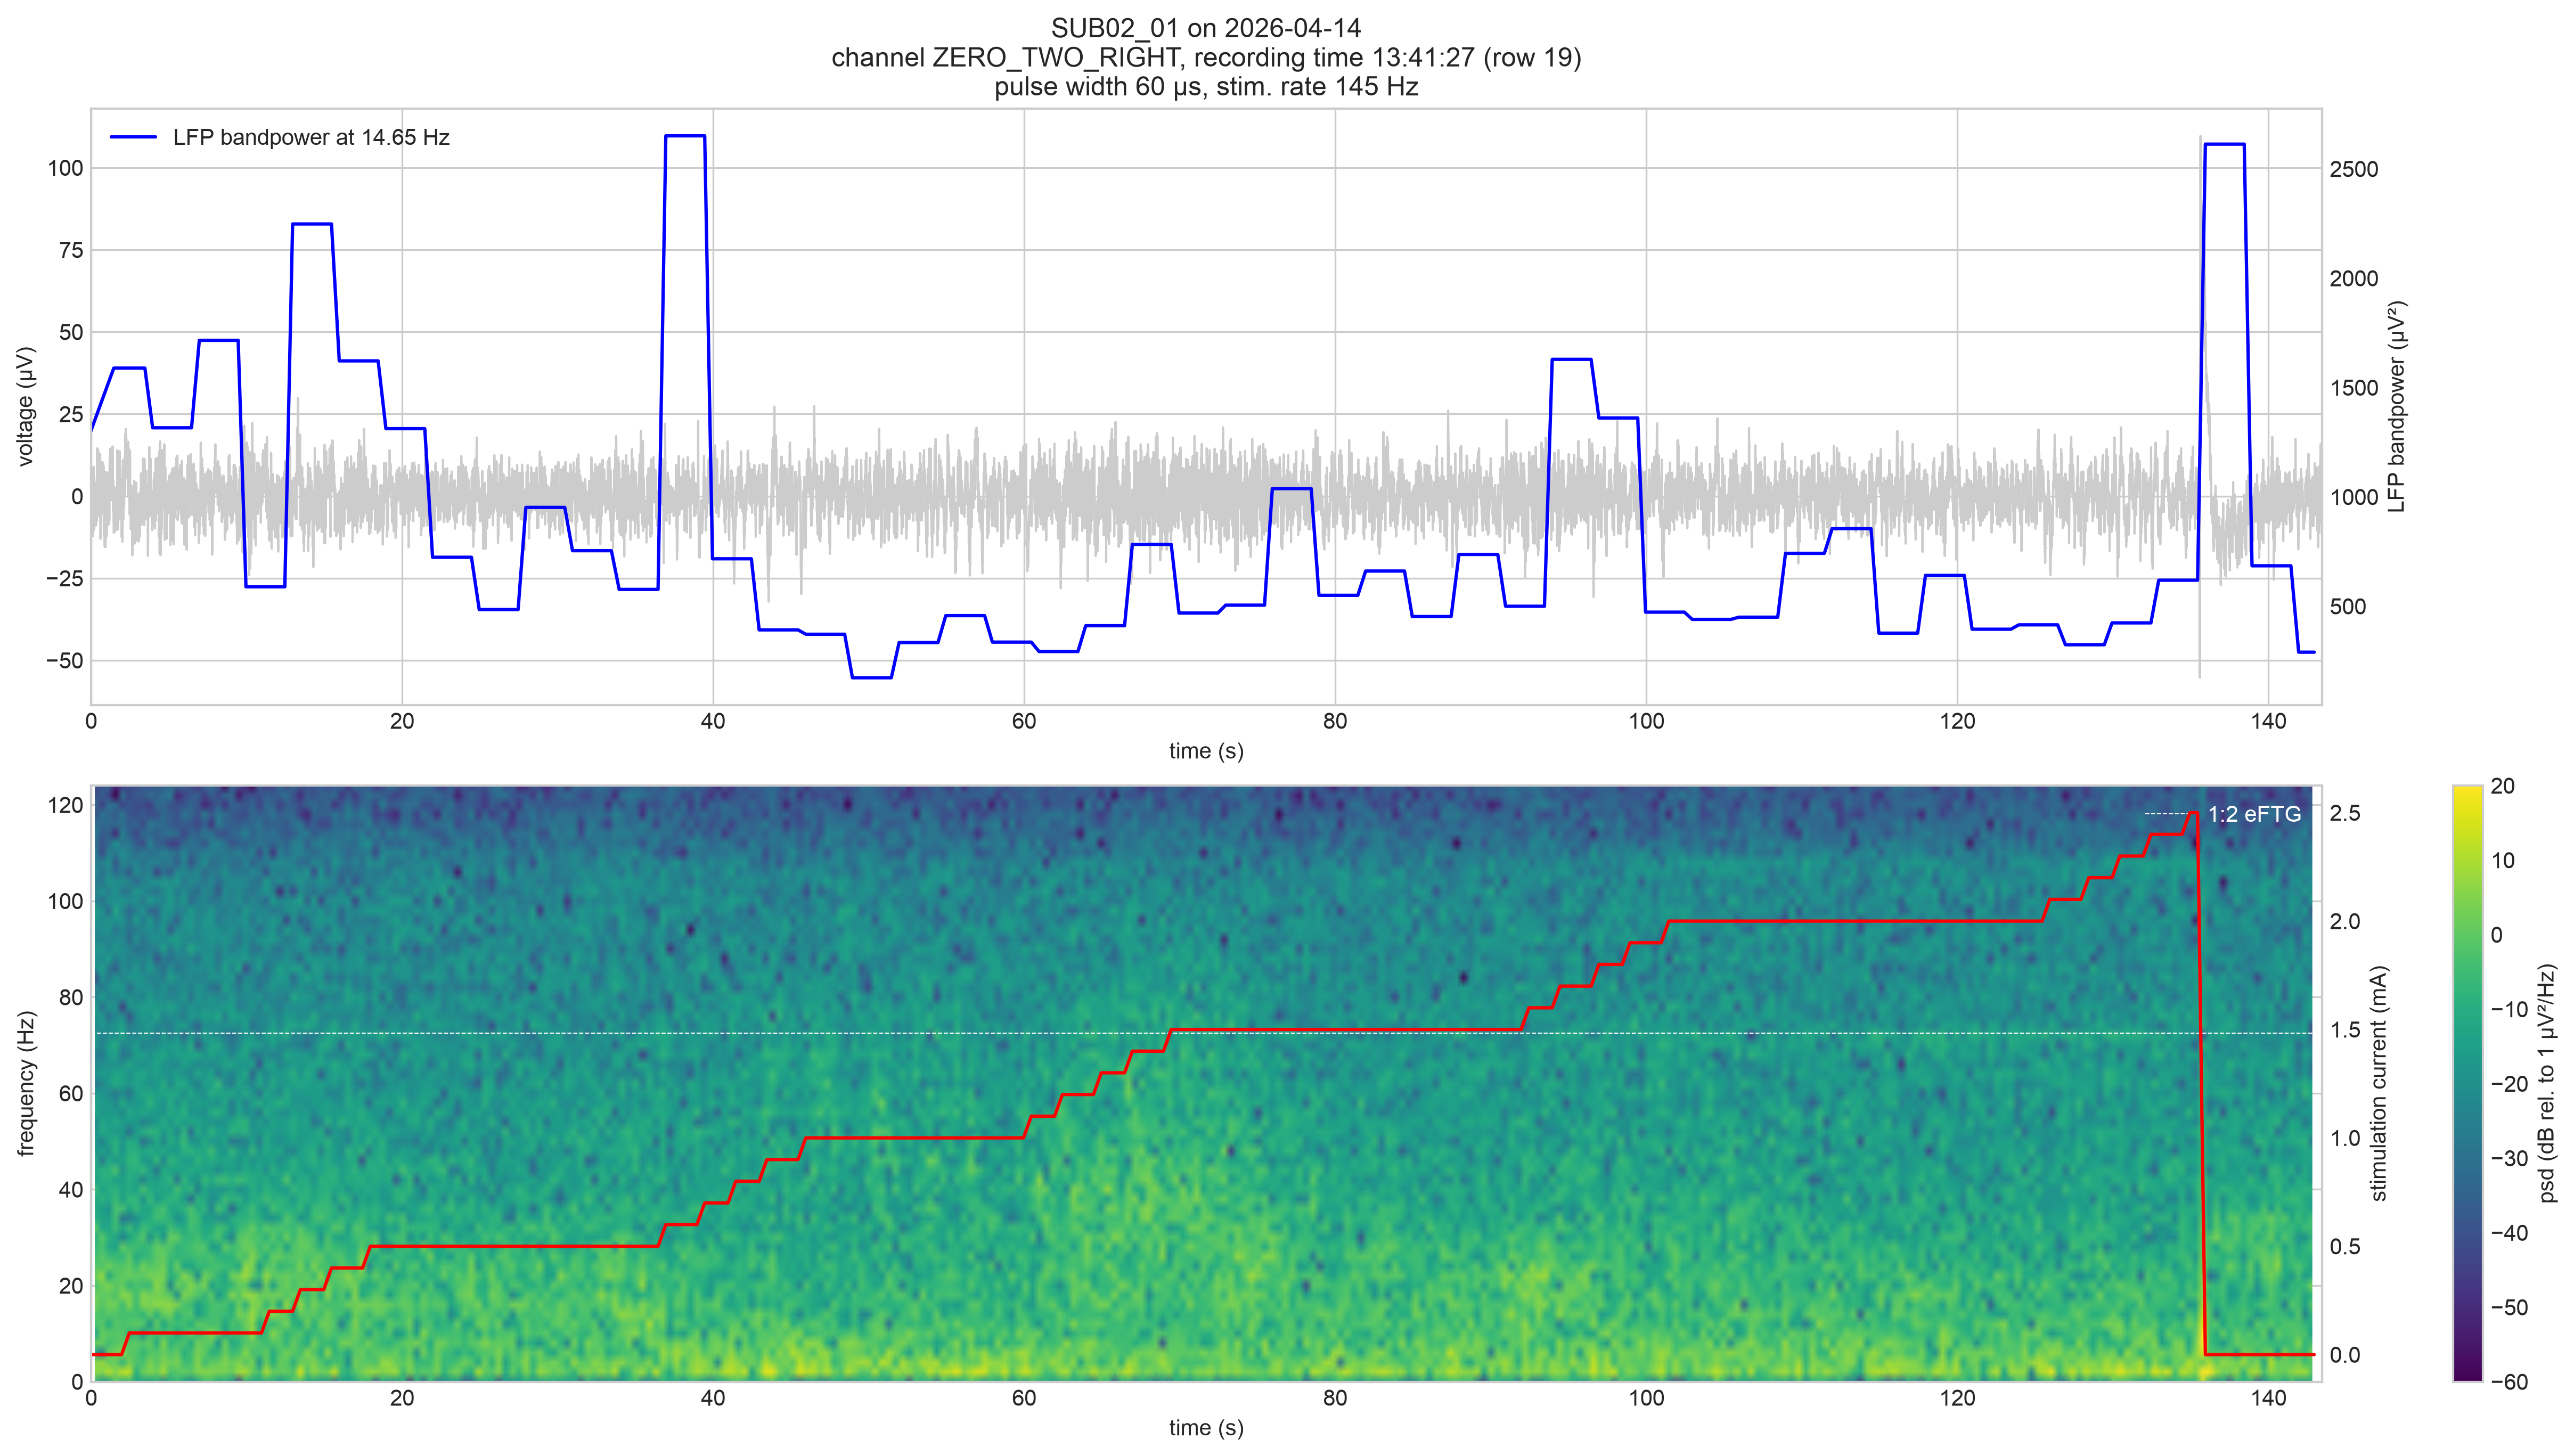

In [ ]:
plot_sample(bstd.iloc[19])

In [ ]:
os.makedirs("figures/BrainSenseTimeDomain", exist_ok=True)
bstd_filt = bstd[bstd.duration_s > 60].copy()
bstd_filt = bstd_filt.reset_index(names='name')

for sample in tqdm(bstd_filt.itertuples(), total=len(bstd_filt), desc="plotting"):
    plot_sample(sample)
    plt.savefig(
        f"figures/BrainSenseTimeDomain/{sample.patient}_{sample.visit}-ch{sample.Channel}-row{sample.name}.png",
        pad_inches="layout",
    )
    plt.close()

plotting:  10%|█         | 15/145 [00:15<02:05,  1.04it/s]/var/folders/13/4ntxcq_x1jn9zqt0l3s8l1vw0000gn/T/ipykernel_5060/3712407371.py:7: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
plotting: 100%|██████████| 145/145 [02:44<00:00,  1.13s/it]
